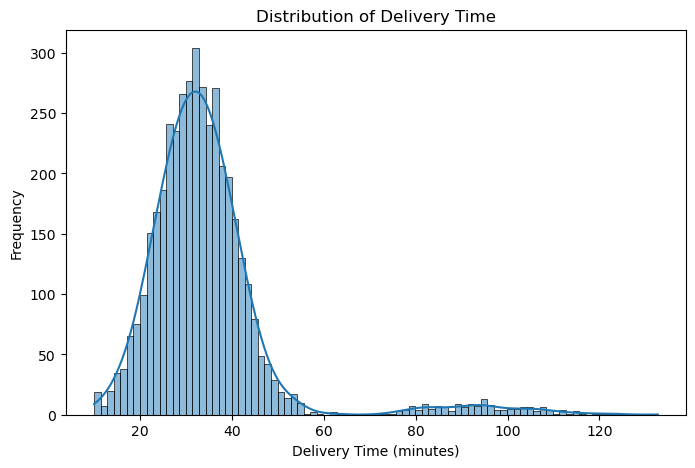

Skewness: 2.8770611473024483
Mean delivery time: 34.541809523809526
Median delivery time: 32.5
The median is more honest to advertise because the delivery times are right-skewed and extreme long deliveries can pull the mean upward.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("food_delivery_orders.csv")

# Display first few rows
df.head()
# Q1: Distribution of delivery time

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='delivery_time_min',
    kde=True
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Frequency")
plt.show()


# Calculate skewness
skewness = df['delivery_time_min'].skew()

# Calculate mean and median
mean_delivery = df['delivery_time_min'].mean()
median_delivery = df['delivery_time_min'].median()

print("Skewness:", skewness)
print("Mean delivery time:", mean_delivery)
print("Median delivery time:", median_delivery)

if mean_delivery > median_delivery:
    print("The median is more honest to advertise because the delivery times are right-skewed and extreme long deliveries can pull the mean upward.")
elif mean_delivery < median_delivery:
    print("The median is more honest because it is less affected by unusually short or long deliveries.")
else:
    print("Mean and median are similar, so either can reasonably represent the typical delivery time.")

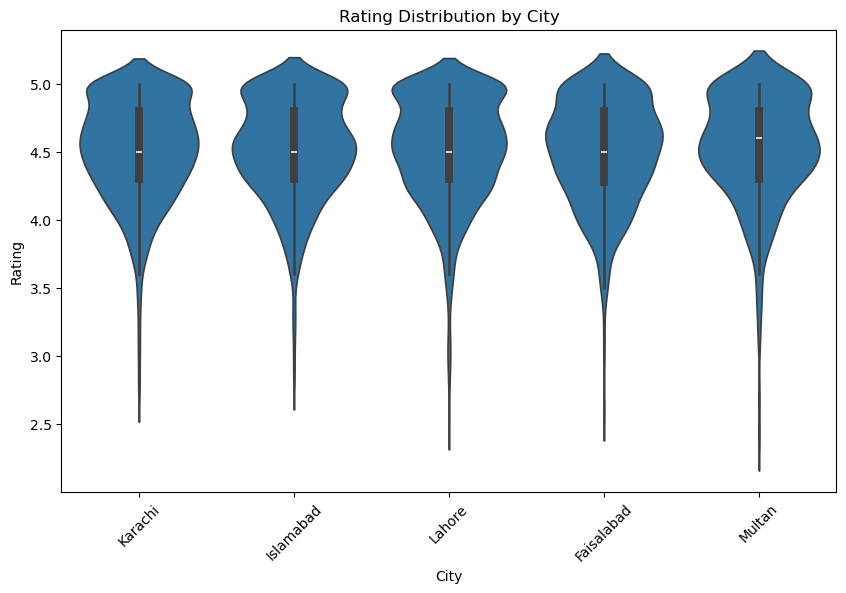

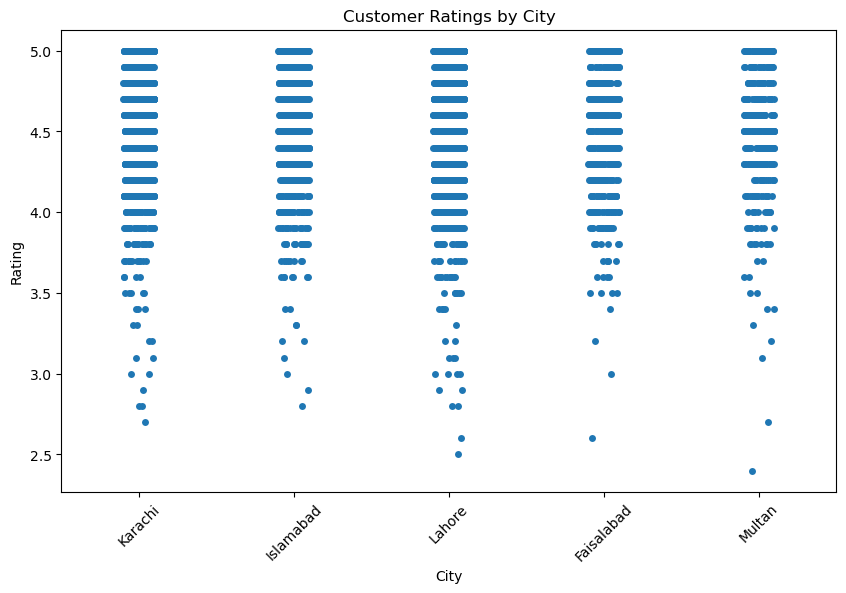

                mean  median       std  min  max
city                                            
Faisalabad  4.490041     4.5  0.384213  2.6  5.0
Islamabad   4.512216     4.5  0.373966  2.8  5.0
Karachi     4.508255     4.5  0.380484  2.7  5.0
Lahore      4.511027     4.5  0.396755  2.5  5.0
Multan      4.520984     4.6  0.400584  2.4  5.0
Most inconsistent city: Multan
Standard deviation: 0.4005840732702126


In [2]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='city',
    y='rating'
)

plt.title("Rating Distribution by City")
plt.xlabel("City")
plt.ylabel("Rating")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(10, 6))

sns.stripplot(
    data=df,
    x='city',
    y='rating',
    jitter=True
)

plt.title("Customer Ratings by City")
plt.xlabel("City")
plt.ylabel("Rating")
plt.xticks(rotation=45)
plt.show()

city_rating_stats = df.groupby('city')['rating'].agg(
    ['mean', 'median', 'std', 'min', 'max']
)

print(city_rating_stats)

most_inconsistent_city = city_rating_stats['std'].idxmax()

print("Most inconsistent city:", most_inconsistent_city)
print("Standard deviation:", city_rating_stats.loc[most_inconsistent_city, 'std'])

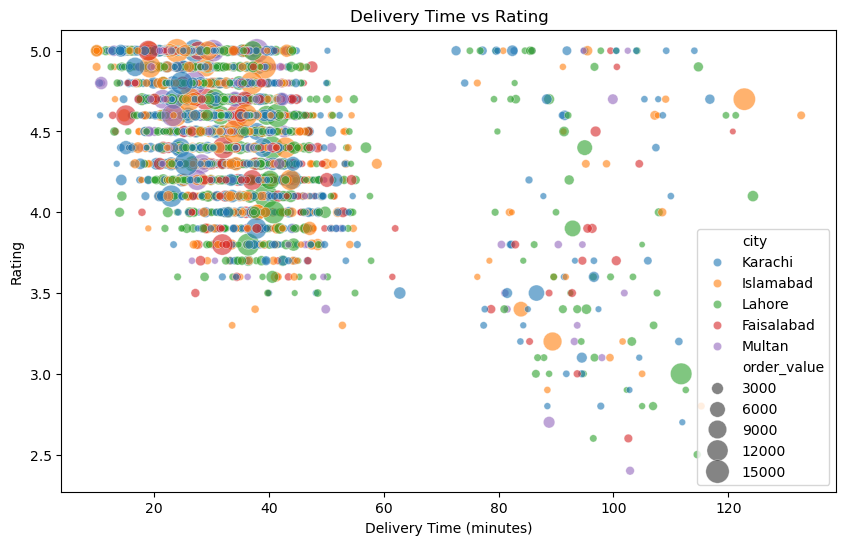

      delivery_time_min  rating   order_value        city
0                  36.2     4.5   2768.000000     Karachi
1                  23.3     4.8   4979.000000     Karachi
2                  39.6     4.2   4008.000000     Karachi
3                  35.8     4.5   3260.000000   Islamabad
10                 46.9     4.5   1541.000000     Karachi
...                 ...     ...           ...         ...
4177               88.4     4.7   2218.000000     Karachi
4179               33.8     5.0   2043.000000   Islamabad
4182               28.3     4.7   1363.000000  Faisalabad
4188               38.7     4.8   1717.000000  Faisalabad
4193               24.8     4.8  14203.917038     Karachi

[1050 rows x 4 columns]


In [4]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='delivery_time_min',
    y='rating',
    hue='city',
    size='order_value',
    sizes=(20, 300),
    alpha=0.6
)

plt.title("Delivery Time vs Rating")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Rating")

plt.show()

high_value = df[df['order_value'] >= df['order_value'].quantile(0.75)]

print(high_value[['delivery_time_min', 'rating', 'order_value', 'city']])

Index(['order_value', 'discount_percent', 'delivery_time_min', 'rating',
       'profit_per_order'],
      dtype='object')
Pearson Correlation:
                   order_value  discount_percent  delivery_time_min    rating  \
order_value           1.000000         -0.011191           0.002202  0.003122   
discount_percent     -0.011191          1.000000           0.013286 -0.006129   
delivery_time_min     0.002202          0.013286           1.000000 -0.445474   
rating                0.003122         -0.006129          -0.445474  1.000000   
profit_per_order     -0.657144         -0.081982          -0.030879  0.014360   

                   profit_per_order  
order_value               -0.657144  
discount_percent          -0.081982  
delivery_time_min         -0.030879  
rating                     0.014360  
profit_per_order           1.000000  
Spearman Correlation:
                   order_value  discount_percent  delivery_time_min    rating  \
order_value           1.000000        

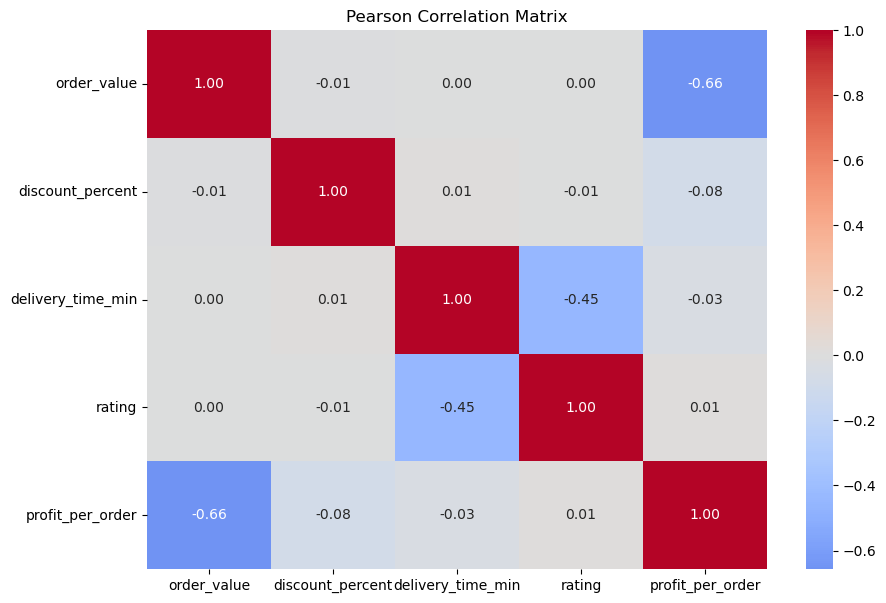

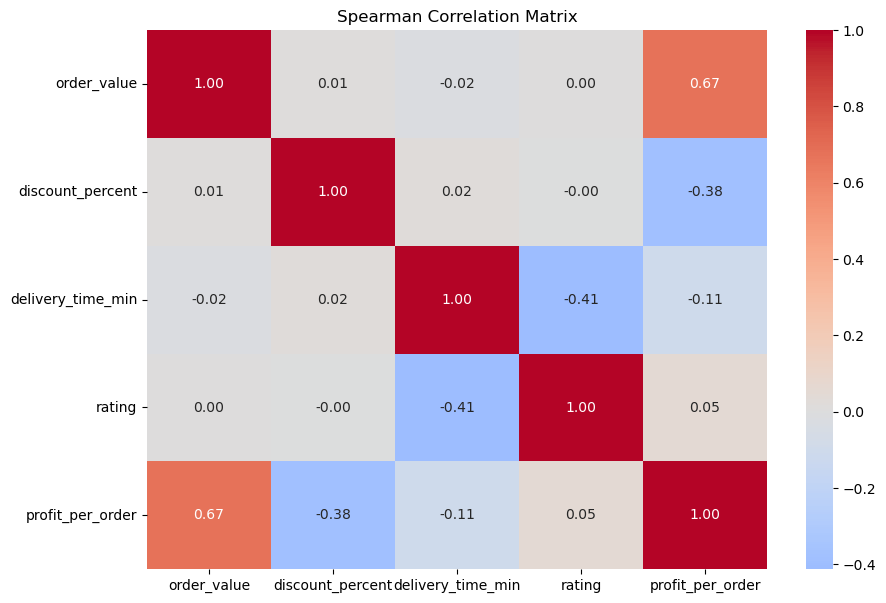

Pair with largest disagreement: ('order_value', 'profit_per_order')
Difference: 1.330258542760049


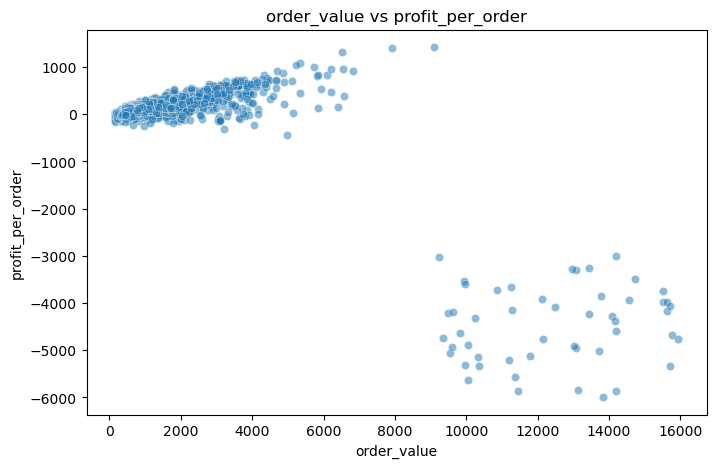

        order_value  profit_per_order
count   4200.000000       4200.000000
mean    1148.395776         57.370067
std     1513.776254        524.064820
min      150.000000      -5994.457891
25%      490.000000         22.000000
50%      740.500000         80.000000
75%     1259.250000        159.000000
max    15943.033840       1423.000000
       order_value  profit_per_order
3992  15943.033840      -4772.648572
220   15759.392549      -4685.768174
2175  15719.098814      -4063.966240
2834  15701.280526      -5327.069945
1742  15635.895703      -3970.654225
1638  15613.141998      -4162.819250
2878  15517.582288      -3750.659733
1121  15507.778588      -3988.485470
2084  14731.924051      -3499.421195
2281  14552.263046      -3934.479132
      order_value  profit_per_order
1459       9086.0            1423.0
1395       7917.0            1405.0
2965       6523.0            1313.0
374        5349.0            1089.0
4149       5235.0            1034.0
1315       5741.0             995.0

In [5]:
numeric_df = df.select_dtypes(include='number')

print(numeric_df.columns)

pearson_corr = numeric_df.corr(method='pearson')

print("Pearson Correlation:")
print(pearson_corr)

spearman_corr = numeric_df.corr(method='spearman')

print("Spearman Correlation:")
print(spearman_corr)

plt.figure(figsize=(10, 7))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Pearson Correlation Matrix")
plt.show()

plt.figure(figsize=(10, 7))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Spearman Correlation Matrix")
plt.show()

difference = abs(pearson_corr - spearman_corr)

# Remove diagonal
np.fill_diagonal(difference.values, np.nan)

max_difference = difference.stack().idxmax()
max_value = difference.stack().max()

print("Pair with largest disagreement:", max_difference)
print("Difference:", max_value)

var1 = max_difference[0]
var2 = max_difference[1]

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x=var1,
    y=var2,
    alpha=0.5
)

plt.title(f"{var1} vs {var2}")
plt.xlabel(var1)
plt.ylabel(var2)
plt.show()


print(df[[var1, var2]].describe())

print(df.nlargest(10, var1)[[var1, var2]])
print(df.nlargest(10, var2)[[var1, var2]])


restaurant_category       Cafe  Cloud Kitchen    Dessert  Fast Food  \
city                                                                  
Faisalabad           67.295455      65.779748 -70.312281  20.222750   
Islamabad           -13.499649      57.011427 -27.884178  37.177258   
Karachi             -38.901838     136.745480  75.240260  15.375665   
Lahore               52.345680     137.614221  65.515000  10.618693   
Multan               60.137931     -82.783323  55.865385 -40.784432   
All                  14.648580      91.829915  31.277856  13.613870   

restaurant_category  Fine Dining        All  
city                                         
Faisalabad            293.695652  51.891636  
Islamabad             153.117851  35.491634  
Karachi               302.801418  74.101668  
Lahore                159.818290  71.552572  
Multan                285.181818  12.622372  
All                   228.922310  57.370067  


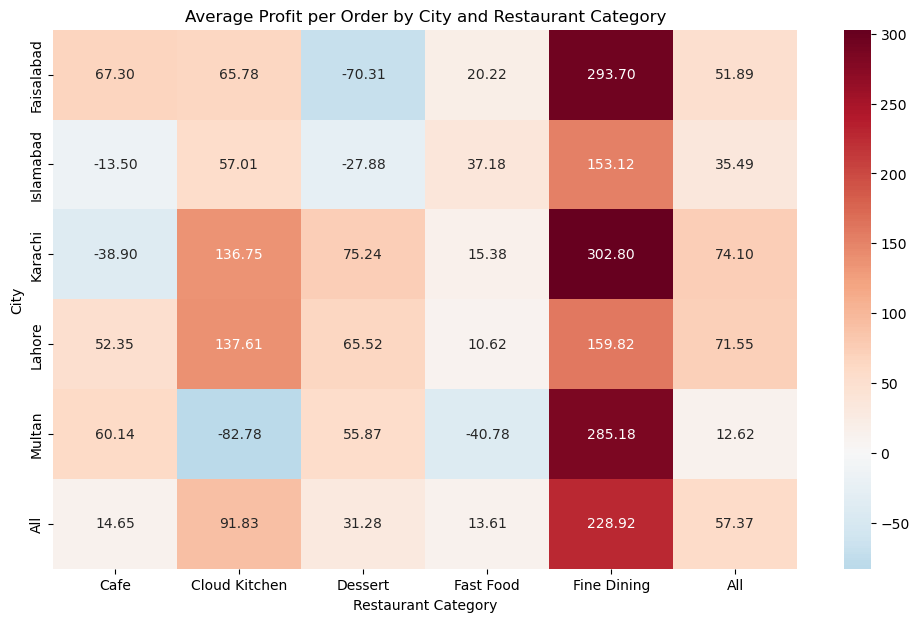

Most profitable combination: ('Karachi', 'Fine Dining')
Average profit per order: 302.8014184397163
Revenue table:
restaurant_category           Cafe  Cloud Kitchen        Dessert  \
city                                                               
Faisalabad            56093.000000  205515.673093   58415.968787   
Islamabad            116804.465053  342842.347073  105370.117698   
Karachi              205017.310881  371410.101760   79235.000000   
Lahore               171131.144319  449766.645395  101385.000000   
Multan                51438.000000  181931.615414   25374.000000   

restaurant_category      Fast Food    Fine Dining  
city                                               
Faisalabad           145852.943873  123173.000000  
Islamabad            203444.042145  270610.217266  
Karachi              288490.379933  371893.000000  
Lahore               379476.867148  336923.842229  
Multan               100182.578649   81485.000000  

Top revenue-generating combination:
('Lahor

In [7]:
pivot = pd.pivot_table(
    df,
    index='city',
    columns='restaurant_category',
    values='profit_per_order',
    aggfunc='mean',
    margins=True
)

print(pivot)


plt.figure(figsize=(12, 7))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0
)

plt.title("Average Profit per Order by City and Restaurant Category")
plt.xlabel("Restaurant Category")
plt.ylabel("City")

plt.show()


pivot_without_totals = pivot.drop(index='All', columns='All')

best_combination = pivot_without_totals.stack().idxmax()
best_profit = pivot_without_totals.stack().max()

print("Most profitable combination:", best_combination)
print("Average profit per order:", best_profit)

revenue_pivot = pd.pivot_table(
    df,
    index='city',
    columns='restaurant_category',
    values='order_value',
    aggfunc='sum'
)

print("Revenue table:")
print(revenue_pivot)

print("\nTop revenue-generating combination:")
print(revenue_pivot.stack().idxmax())

print("Revenue:")
print(revenue_pivot.stack().max())



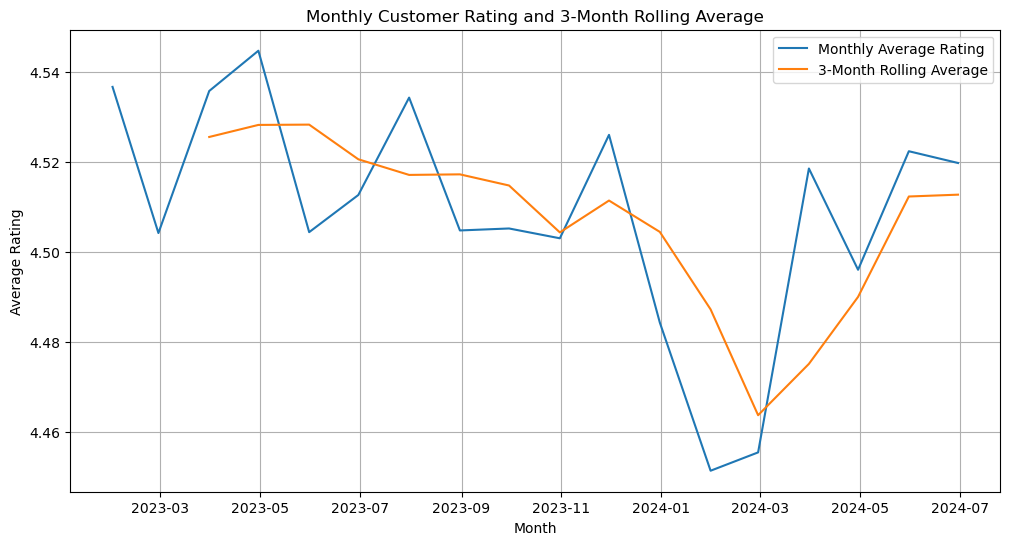

First rolling average: 4.525532878684654
Last rolling average: 4.512726372382569
Customer satisfaction shows an overall downward trend.


In [8]:
# Convert order_date to datetime
df['order_date'] = pd.to_datetime(df['order_date'])

# Set date as index
df_time = df.set_index('order_date')

# Monthly average rating
monthly_rating = df_time['rating'].resample('ME').mean()

# 3-month rolling average
rolling_rating = monthly_rating.rolling(window=3).mean()

# Plot
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_rating.index,
    monthly_rating,
    label='Monthly Average Rating'
)

plt.plot(
    rolling_rating.index,
    rolling_rating,
    label='3-Month Rolling Average'
)

plt.title("Monthly Customer Rating and 3-Month Rolling Average")
plt.xlabel("Month")
plt.ylabel("Average Rating")

plt.legend()
plt.grid(True)

plt.show()
print("First rolling average:", rolling_rating.dropna().iloc[0])
print("Last rolling average:", rolling_rating.dropna().iloc[-1])

if rolling_rating.dropna().iloc[-1] > rolling_rating.dropna().iloc[0]:
    print("Customer satisfaction shows an overall upward trend.")
elif rolling_rating.dropna().iloc[-1] < rolling_rating.dropna().iloc[0]:
    print("Customer satisfaction shows an overall downward trend.")
else:
    print("Customer satisfaction is approximately flat.")

    


In [11]:
df['heavy_discount'] = df['discount_percent'] > 20

print(df[['discount_percent', 'heavy_discount']].head())


   discount_percent  heavy_discount
0              25.0            True
1              44.8            True
2              11.9           False
3               8.3           False
4              13.5           False


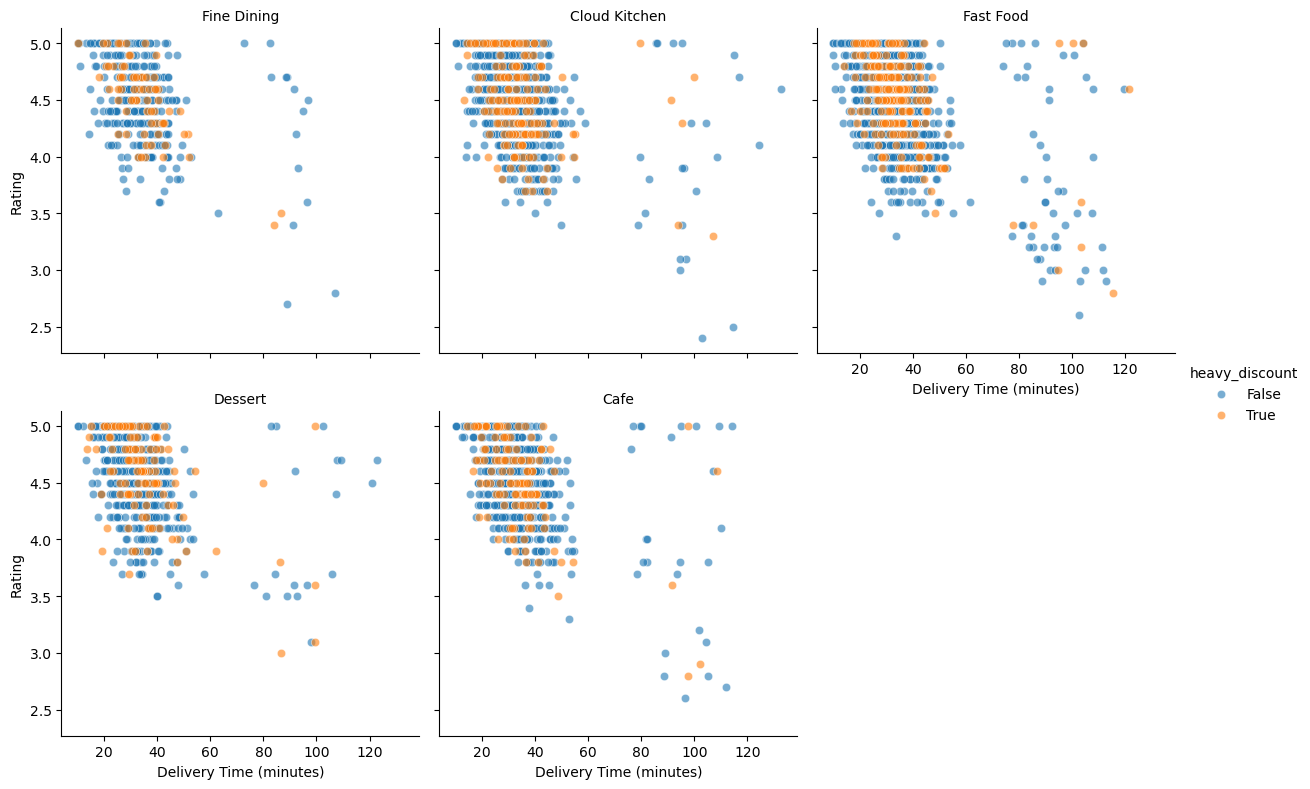

In [12]:
g = sns.FacetGrid(
    df,
    col='restaurant_category',
    hue='heavy_discount',
    col_wrap=3,
    height=4
)

g.map(
    sns.scatterplot,
    'delivery_time_min',
    'rating',
    alpha=0.6
)

g.add_legend()

g.set_axis_labels(
    "Delivery Time (minutes)",
    "Rating"
)

g.set_titles("{col_name}")

plt.show()

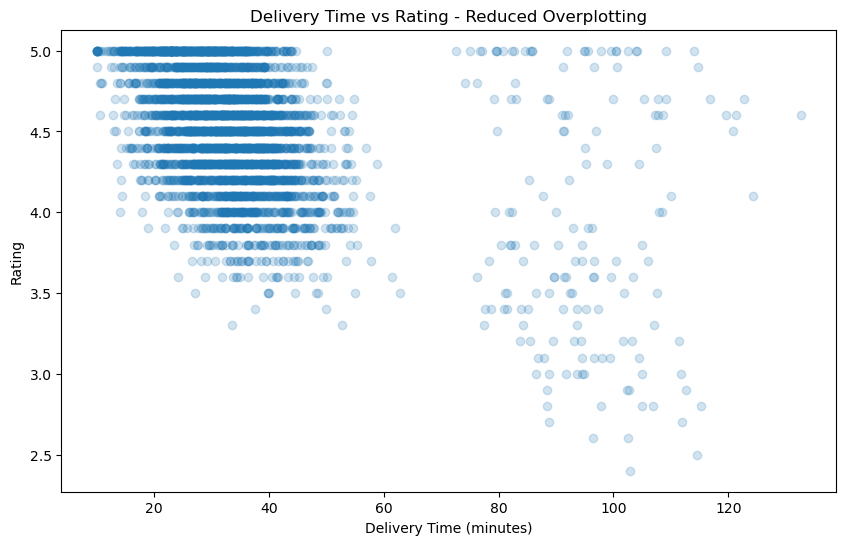

In [14]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['delivery_time_min'],
    df['rating'],
    alpha=0.2
)

plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Rating")
plt.title("Delivery Time vs Rating - Reduced Overplotting")

plt.show()

In [15]:
# Use 75th percentile as threshold for unusually long delivery
long_threshold = df['delivery_time_min'].quantile(0.75)

long_orders = df[df['delivery_time_min'] >= long_threshold]

best_long = long_orders.loc[long_orders['rating'].idxmax()]

print("Best rating despite long delivery:")
print(best_long)

Best rating despite long delivery:
order_date             2023-01-21 00:00:00
city                                Lahore
restaurant_category                   Cafe
cuisine                         Sandwiches
order_value                          341.0
discount_percent                      10.5
delivery_time_min                     79.5
rating                                 5.0
profit_per_order                     -58.0
heavy_discount                       False
Name: 143, dtype: object


In [16]:
# Use 25th percentile as threshold for unusually fast delivery
fast_threshold = df['delivery_time_min'].quantile(0.25)

fast_orders = df[df['delivery_time_min'] <= fast_threshold]

worst_fast = fast_orders.loc[fast_orders['rating'].idxmin()]

print("Worst rating despite fast delivery:")
print(worst_fast)

Worst rating despite fast delivery:
order_date             2024-03-09 00:00:00
city                                Lahore
restaurant_category              Fast Food
cuisine                            Burgers
order_value                          636.0
discount_percent                      10.8
delivery_time_min                     24.1
rating                                 3.6
profit_per_order                      59.0
heavy_discount                       False
Name: 3329, dtype: object


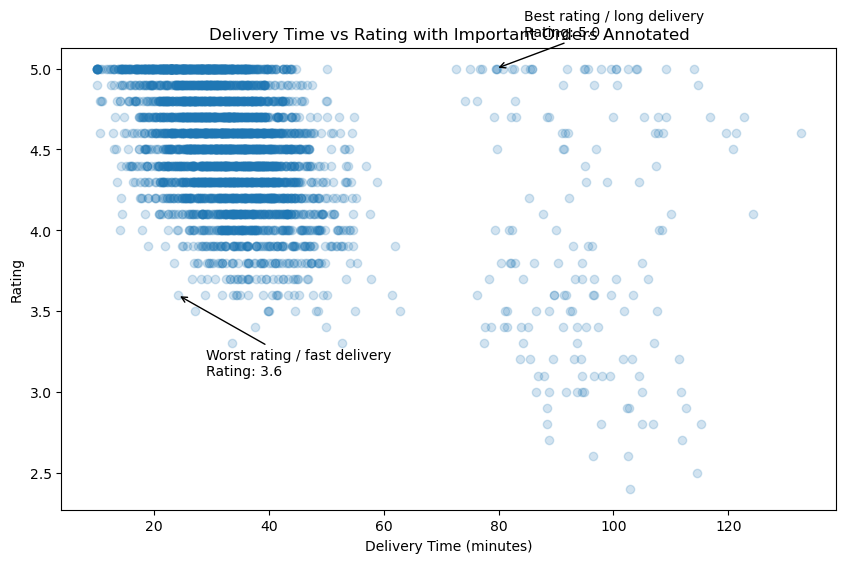

In [17]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['delivery_time_min'],
    df['rating'],
    alpha=0.2
)

# Best rating despite long delivery
plt.annotate(
    f"Best rating / long delivery\nRating: {best_long['rating']}",
    xy=(
        best_long['delivery_time_min'],
        best_long['rating']
    ),
    xytext=(
        best_long['delivery_time_min'] + 5,
        best_long['rating'] + 0.2
    ),
    arrowprops=dict(arrowstyle='->')
)

# Worst rating despite fast delivery
plt.annotate(
    f"Worst rating / fast delivery\nRating: {worst_fast['rating']}",
    xy=(
        worst_fast['delivery_time_min'],
        worst_fast['rating']
    ),
    xytext=(
        worst_fast['delivery_time_min'] + 5,
        worst_fast['rating'] - 0.5
    ),
    arrowprops=dict(arrowstyle='->')
)

plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Rating")
plt.title("Delivery Time vs Rating with Important Orders Annotated")

plt.show()

In [18]:
print(
    "Transparency (alpha) is used because the repeated rating values create "
    "overplotting, and lowering opacity makes overlapping observations easier to see."
)

Transparency (alpha) is used because the repeated rating values create overplotting, and lowering opacity makes overlapping observations easier to see.
